In [3]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.metrics import accuracy_score, roc_curve

import warnings
warnings.filterwarnings("ignore")

df = pd.read_csv("heart.csv")

describe = df.describe()

print(describe)

print(df.info())
print(df.isnull().sum())

              age         sex          cp      trtbps        chol         fbs  \
count  303.000000  303.000000  303.000000  303.000000  303.000000  303.000000   
mean    54.366337    0.683168    0.966997  131.623762  246.264026    0.148515   
std      9.082101    0.466011    1.032052   17.538143   51.830751    0.356198   
min     29.000000    0.000000    0.000000   94.000000  126.000000    0.000000   
25%     47.500000    0.000000    0.000000  120.000000  211.000000    0.000000   
50%     55.000000    1.000000    1.000000  130.000000  240.000000    0.000000   
75%     61.000000    1.000000    2.000000  140.000000  274.500000    0.000000   
max     77.000000    1.000000    3.000000  200.000000  564.000000    1.000000   

          restecg    thalachh        exng     oldpeak         slp         caa  \
count  303.000000  303.000000  303.000000  303.000000  303.000000  303.000000   
mean     0.528053  149.646865    0.326733    1.039604    1.399340    0.729373   
std      0.525860   22.9051

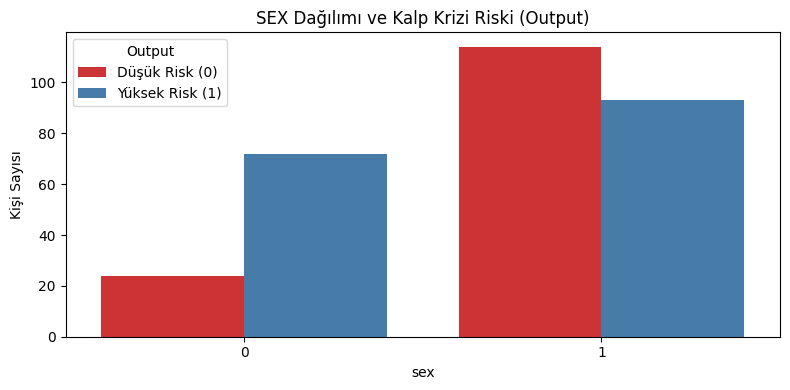

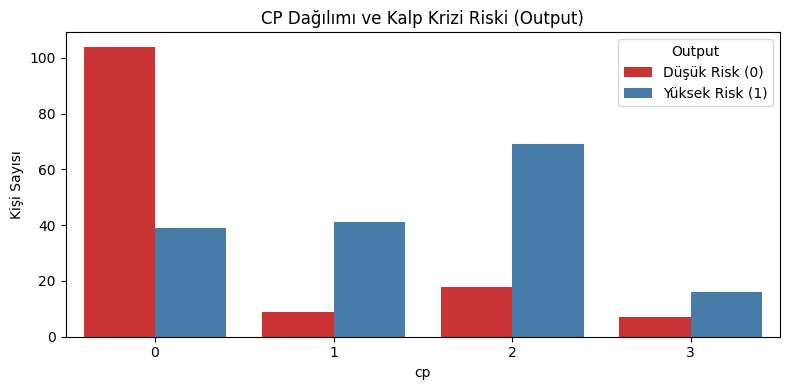

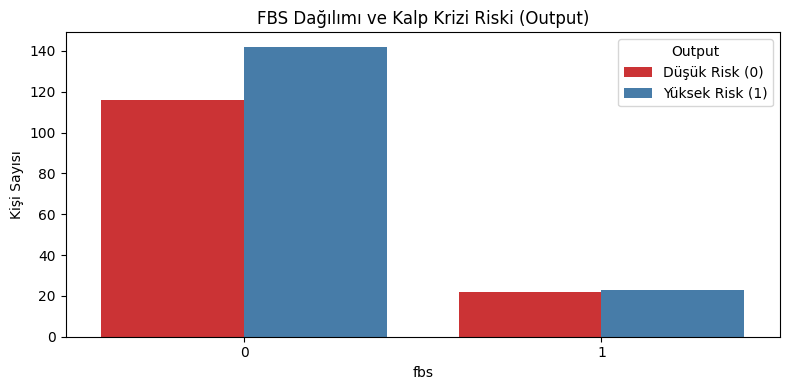

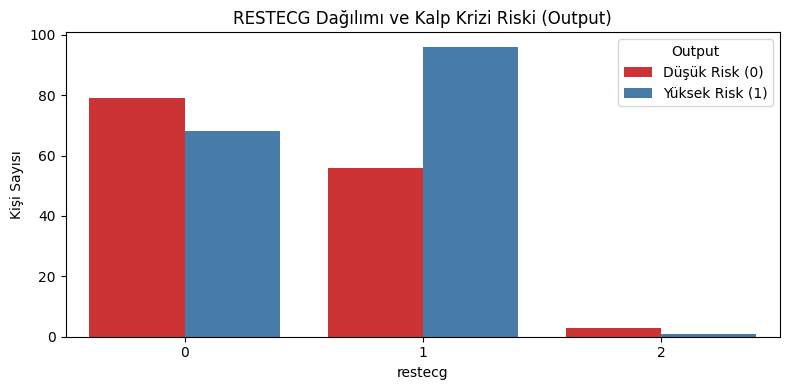

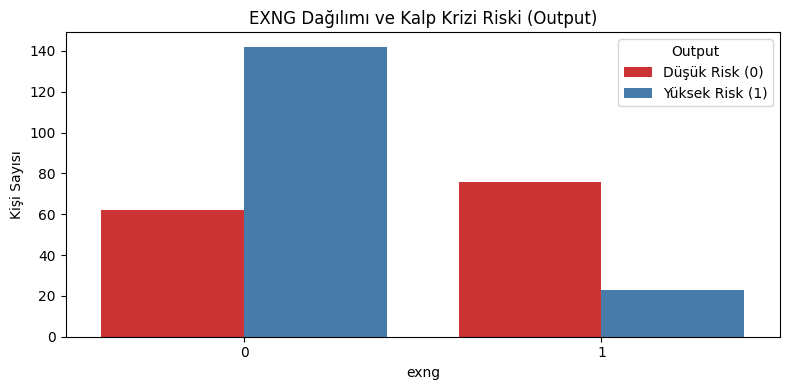

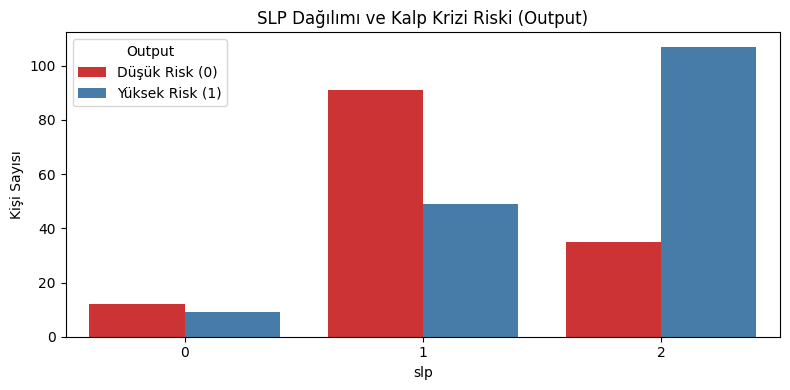

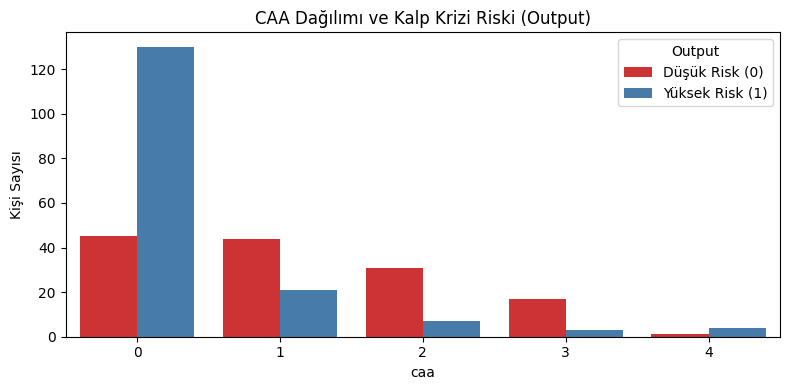

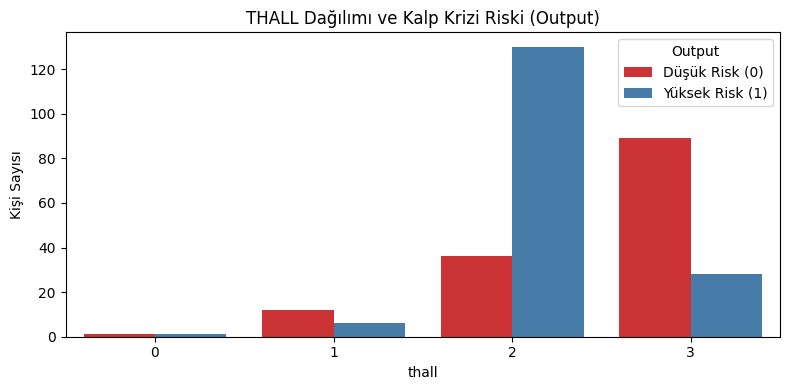

In [6]:
# Categorical and numerical features
categorical_features = ['sex', 'cp', 'fbs', 'restecg', 'exng', 'slp', 'caa', 'thall']
df_categorical = df.loc[:, categorical_features + ['output']]

for i in categorical_features:
    plt.figure(figsize=(8, 4))
    sns.countplot(x=i, data=df_categorical, hue='output', palette='Set1')
    plt.title(f'{i.upper()} Dağılımı ve Kalp Krizi Riski (Output)')
    plt.xlabel(i)
    plt.ylabel('Kişi Sayısı')
    plt.legend(title='Output', labels=['Düşük Risk (0)', 'Yüksek Risk (1)'])
    plt.tight_layout()
    plt.show()

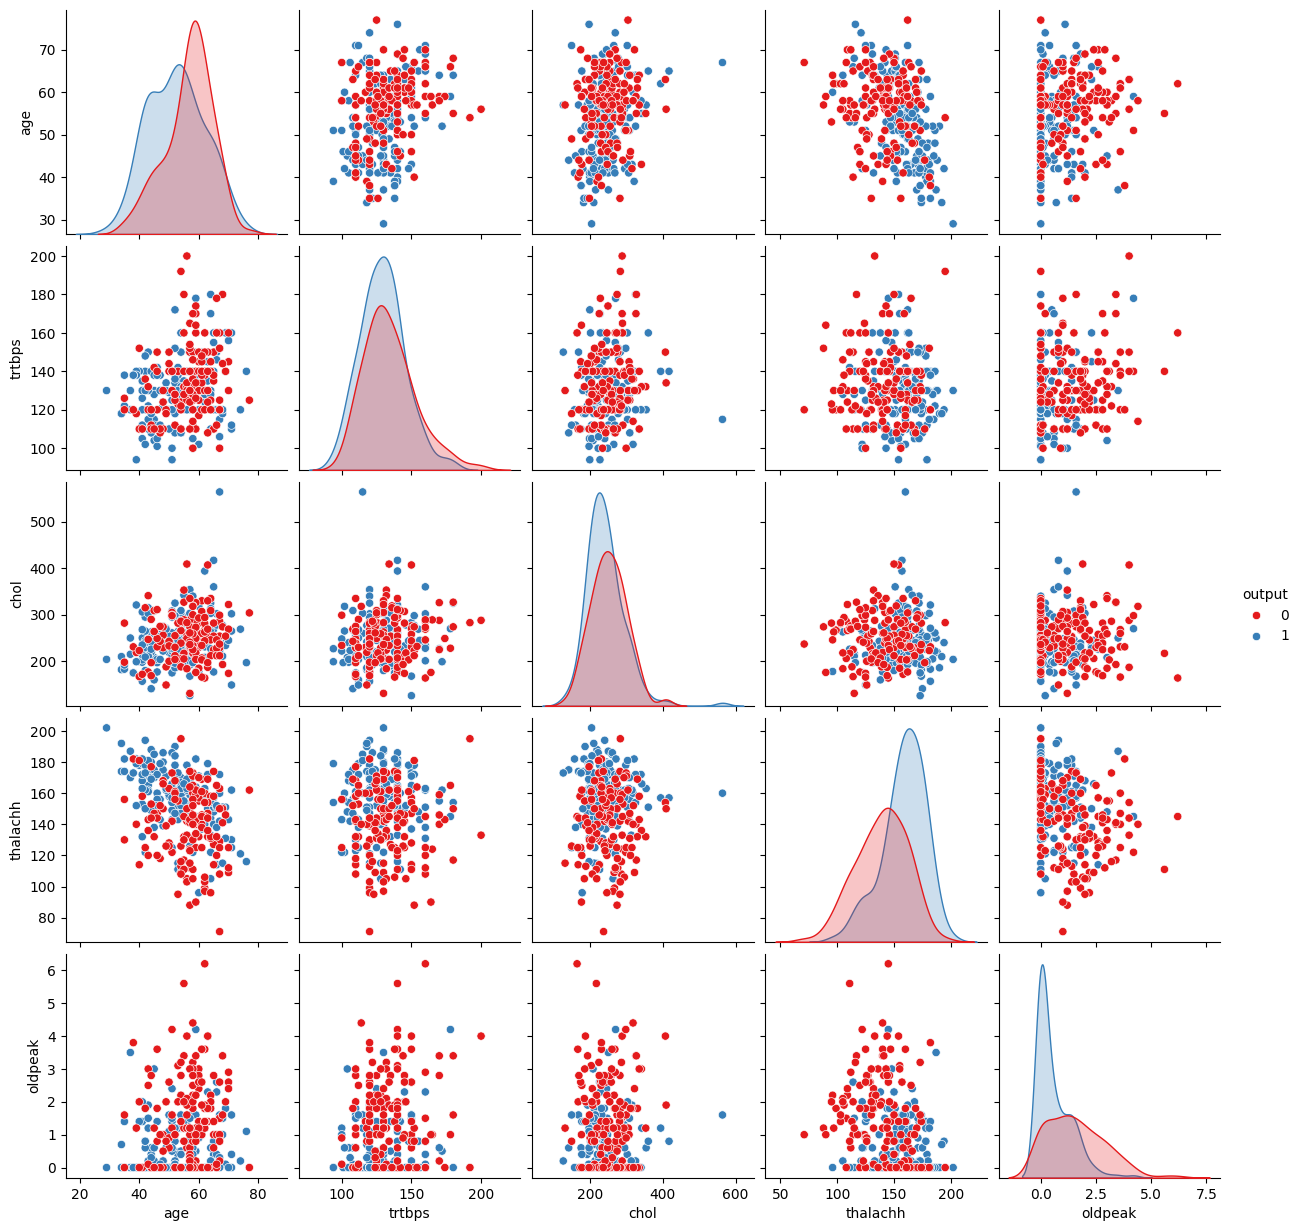

In [7]:
numeric_list = ['age', 'trtbps', 'chol', 'thalachh', 'oldpeak']
df_numeric = df.loc[:, numeric_list + ['output']]
sns.pairplot(df_numeric, hue='output', diag_kind="kde", palette='Set1')
plt.show()

<Axes: >

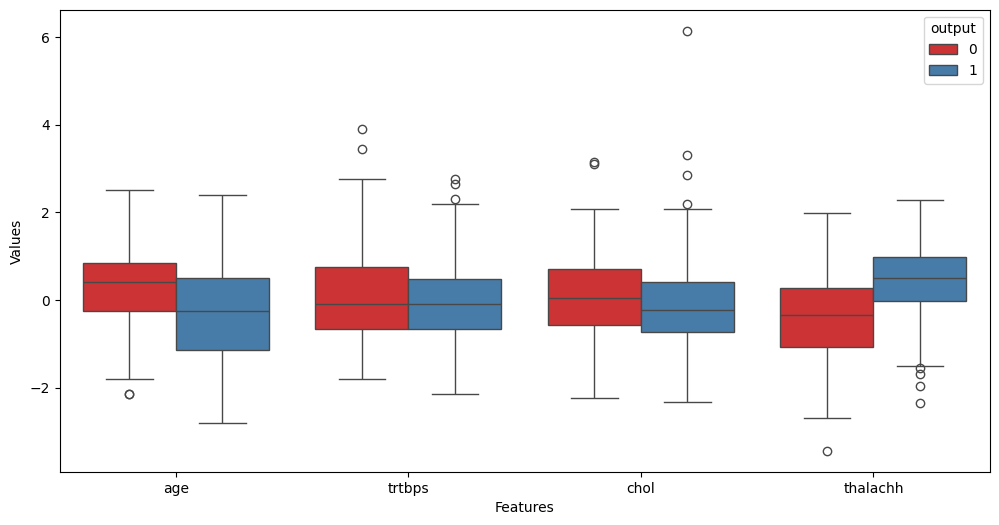

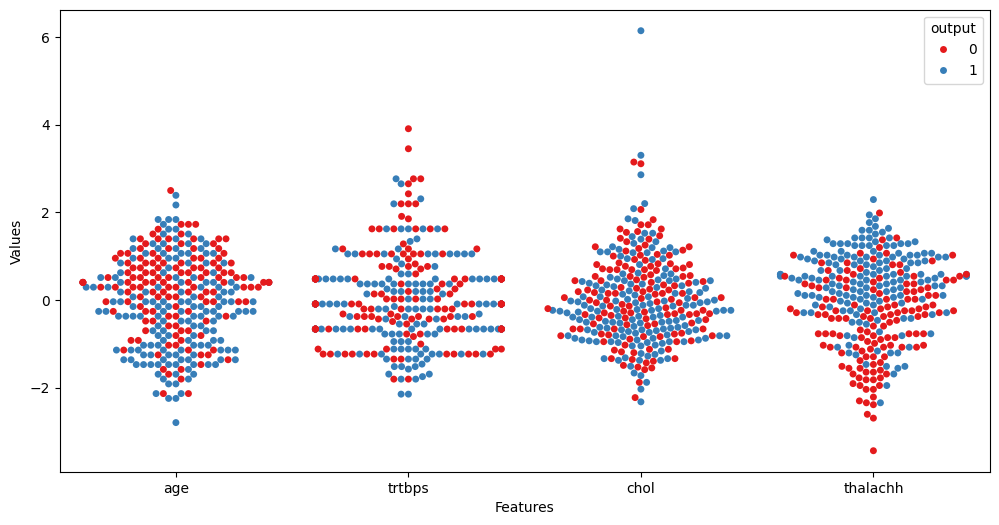

<Figure size 1200x600 with 0 Axes>

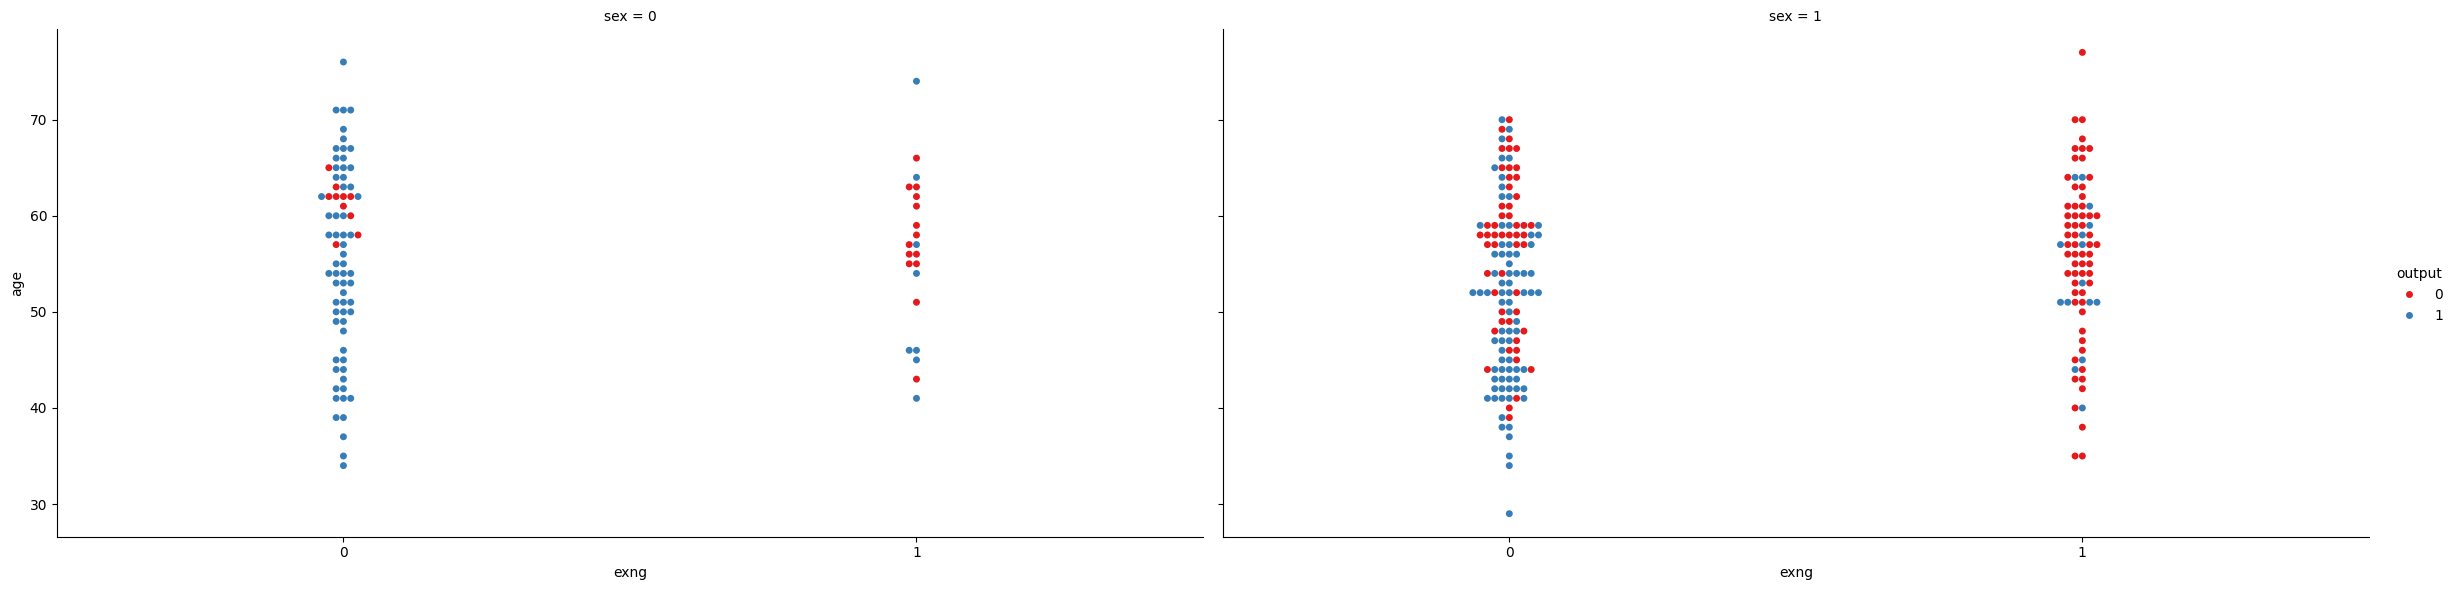

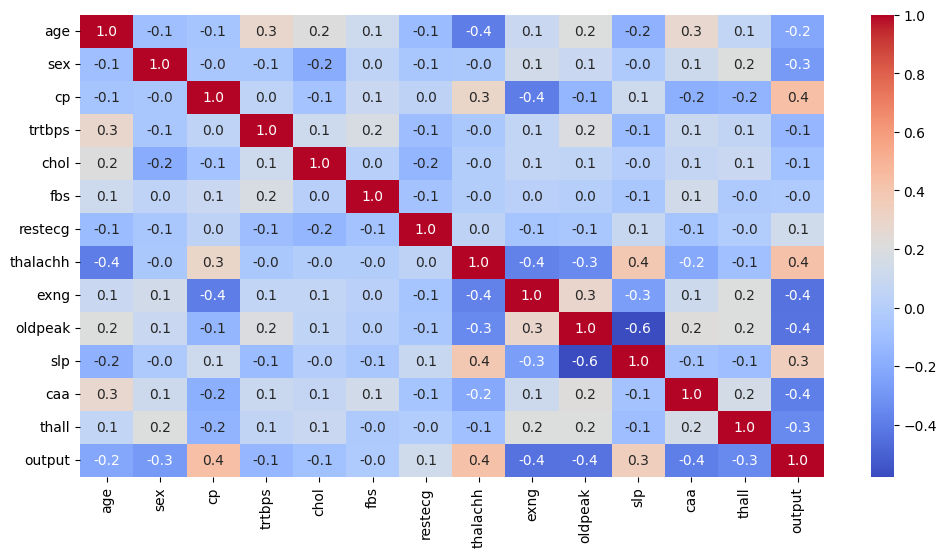

In [24]:
# Eda 
scaler = StandardScaler()
scaled_data = scaler.fit_transform(df[numeric_list[:-1]])
df_dummy = pd.DataFrame(scaled_data, columns=numeric_list[:-1])
df_dummy = pd.concat([df_dummy, df['output']], axis=1)
data_melted = pd.melt(df_dummy, id_vars='output', var_name='Features', value_name='Values')
plt.figure(figsize=(12, 6))
sns.boxplot(x='Features', y='Values', hue='output', data=data_melted, palette='Set1')
plt.figure(figsize=(12, 6))
sns.swarmplot(x='Features', y='Values', hue='output', data=data_melted, palette='Set1')
plt.figure(figsize=(12, 6))
sns.catplot(x="exng", y="age", hue="output",col="sex", kind='swarm',data=df, palette='Set1', height=6, aspect=2)
plt.figure(figsize=(12, 6))
sns.heatmap(df.corr(), annot=True, cmap='coolwarm', fmt=".1f")

In [28]:
# Outlier Detection
outlier_indices = set()

for i in numeric_list[:-1]:
    Q1 = df[i].quantile(0.25)
    Q3 = df[i].quantile(0.75)
    IQR = Q3 - Q1
    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR
    
    current_outliers = df[(df[i] < lower_bound) | (df[i] > upper_bound)].index
    outlier_indices.update(current_outliers)

df.drop(index=list(outlier_indices), inplace=True)
print(f"Temizleme sonrası boyut: {df.shape}")
    

Temizleme sonrası boyut: (288, 14)


Accuracy: 0.6724137931034483


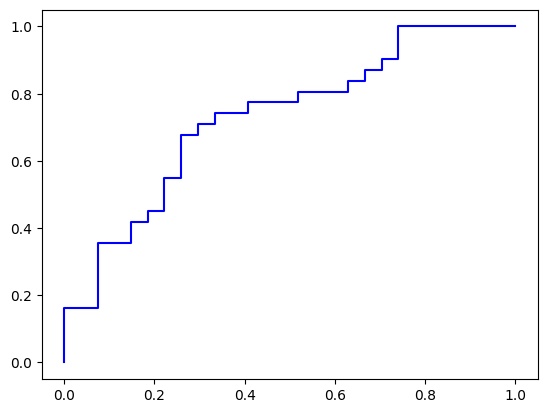

In [33]:
# Modelling

df_copy=df.copy()
df_copy=pd.get_dummies(df_copy, columns=categorical_features, drop_first=True)
X= df_copy.drop('output', axis=1)
y= df_copy['output']

scaler = StandardScaler()
scaled_X = scaler.fit_transform(X[numeric_list[:-1]])

X_train , X_test, y_train, y_test = train_test_split(scaled_X, y, test_size=0.2, random_state=42)

logreg = LogisticRegression()
logreg.fit(X_train, y_train)
y_pred_prob = logreg.predict_proba(X_test)
y_pred = np.argmax(y_pred_prob, axis=1)
print(f"Accuracy: {accuracy_score(y_test, y_pred)}")

# roc curve
fpr, tpr, thresholds = roc_curve(y_test, y_pred_prob[:, 1])
plt.plot(fpr, tpr, color='blue', label='ROC Curve')


In [34]:
# Hyperparameter Tuning


param_grid = {
    'C': [0.1, 1, 10, 100],
    'penalty': ['l1', 'l2'],
    'solver': ['liblinear', 'saga']
}

grid_search = GridSearchCV(LogisticRegression(), param_grid, cv=5, scoring='accuracy')
grid_search.fit(X_train, y_train)

print(f"Best parameters: {grid_search.best_params_}")
print(f"Best cross-validation score: {grid_search.best_score_}")

Best parameters: {'C': 1, 'penalty': 'l1', 'solver': 'liblinear'}
Best cross-validation score: 0.7130434782608697
